# Figure 3. Base-pair scoring against reference geometry

A: how one property is judged against its reference distribution. B: example pairs and their scores. C: where the two flagged pairs lose their points. (The ribose check is Supplementary Fig. S2D.)

In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
RENDERS = ROOT / "data" / "pymol" / "renders"
CROPPED = RENDERS / "cropped"
CROPPED.mkdir(parents=True, exist_ok=True)

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 600, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "pdf.fonttype": 42, "ps.fonttype": 42,
})

def letter(fig, ax, s, dx=-0.014, dy=0.004):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=12, fontweight="bold",
             ha="left", va="bottom")

def letter_drawn(fig, ax, s, dx=-0.014, dy=0.004):
    fig.canvas.draw()
    pts = np.vstack([ln.get_xydata() for ln in ax.lines if len(ln.get_xydata())])
    x, y = ax.transData.transform((pts[:, 0].min(), pts[:, 1].max()))
    fx, fy = fig.transFigure.inverted().transform((x, y))
    fig.text(fx + dx, fy + dy, s, fontsize=12, fontweight="bold",
             ha="left", va="bottom")

def autocrop(name, pad=2, thresh=246):
    src, dst = RENDERS / name, CROPPED / name
    im = Image.open(src).convert("RGB")
    mask = ImageOps.grayscale(im).point(lambda v: 255 if v < thresh else 0)
    box = mask.getbbox()
    if box:
        l, t, r, b = box
        im = im.crop((max(0, l - pad), max(0, t - pad),
                      min(im.width, r + pad), min(im.height, b + pad)))
    im.save(dst)
    return dst

def show_pair(ax, name):
    ax.imshow(plt.imread(autocrop(f"{name}.png")))
    ax.set_xticks([]); ax.set_yticks([])
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(False)

print("renders:", ", ".join(sorted(p.stem for p in RENDERS.glob("1C_*.png"))))

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


renders: 1C_distorted_AU, 1C_ideal_AU, 1C_ideal_GC


In [23]:
# One printed base size for every render in the figure, the same as Figure 4K/L. Measured on the
# six-membered ring (the white hole inside it, the same atoms in every render, so tilt and substituents
# do not bias it): ~162 px in the opening renders of panel A, ~110 px in the 2100-px pair renders of
# panel B and Figure 4. TARGET_SPAN_IN is that hole in inches; the figure is saved at the RSC double-column
# width (6.73 in), so it prints 1:1 and the ring matches Figure 4 printed at the same page width.
TARGET_SPAN_IN = 0.197
PX_PER_PYRIMIDINE = {"3C": 162, "pairs": 110}


In [24]:
import json

import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import ConnectionPatch, Polygon
from matplotlib.ticker import MaxNLocator
from scipy.stats import gaussian_kde

data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

PAIR, LW_CLASS = "A-U", "cWW"
FLIP = {"shear", "stagger", "buckle"}
PROSCO_PREFERRED = 5.0
SEV_CMAP = LinearSegmentedColormap.from_list("sev", ["0.82", "#F4D03F", "#E67E22", "#C0392B"])
SEV_NORM = Normalize(0, 1)
PROSCO = _json("reference/scoring_tables/prosco_distributions.json")["prosco_distributions"]
ZTAB = _json("reference/scoring_tables/z_tables.json")

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

import sys
sys.path.insert(0, str(ROOT / "scripts" / "data_gen"))
from build_prosco_distributions import BANDWIDTH_FACTOR, canonicalize_dataframe
from _vendor.hbond_distance_policy import select_distance_rows

def scoring_kde(group="hbonds", param="distance"):
    df = pd.read_csv(data_file(f"reference/high_quality_features/{group}.csv"))
    df = canonicalize_dataframe(df, group)
    if group == "hbonds":
        df = select_distance_rows(df)
    df = df[(df["bp_type"] == PAIR) & (df["lw_class"] == LW_CLASS)]
    v = df[param].to_numpy(float)
    ok = np.isfinite(v)
    v, ids = v[ok], df["pdb_id"][ok]
    w = per_pdb_weights(ids)
    kde = gaussian_kde(v, weights=w)
    kde.set_bandwidth(kde.factor * BANDWIDTH_FACTOR)
    return v, w, kde

def per_pdb_weights(pdb_ids):
    counts = pdb_ids.value_counts()
    return np.array([1.0 / counts[p] for p in pdb_ids])

def weighted_quantile(values, weights, q):
    order = np.argsort(values)
    v, w = values[order], weights[order]
    cum = np.cumsum(w)
    return float(np.interp(q * cum[-1], cum - w / 2, v))

_to_cg = lambda param, xs: xs

def _entry(table, group, param):
    c = table[group][param]
    return c.get(f"{PAIR}/{LW_CLASS}") or c.get("-".join(PAIR.split("-")[::-1]) + f"/{LW_CLASS}")

def prosco_at(group, param, xs_gc):
    xs = _to_cg(param, xs_gc)
    c = _entry(PROSCO, group, param)
    lo, hi, n = c["support_lo"], c["support_hi"], c["n_bins"]
    pb = np.array(c["prosco_per_bin"], float)
    return pb[np.clip(((xs - lo) / (hi - lo) * n).astype(int), 0, n - 1)]

def zprime_at(group, param, xs_gc):
    xs = _to_cg(param, xs_gc)
    c = _entry(ZTAB, group, param)
    M, sl, su = c["M"], c["sl"], c["su"]
    return (xs - M) / np.where(xs >= M, su, sl)

def severity_at(group, param, xs_gc):
    pr, z = prosco_at(group, param, xs_gc), zprime_at(group, param, xs_gc)
    ramp = np.clip((PROSCO_PREFERRED - pr) / PROSCO_PREFERRED, 0.0, 1.0)
    return np.where(pr >= PROSCO_PREFERRED, 0.0, np.minimum(1.0, np.abs(z) / 5.0) * ramp)

def cal_panel(ax, kind, param, group, xlabel, tail=0.003, pad=0.05, include=()):
    arr, w, kde = scoring_kde(group, param)

    xs = np.linspace(arr.min(), arr.max(), 1200)
    ys = kde(xs)
    seen = xs[ys >= tail * ys.max()]
    span = seen.max() - seen.min()
    xlo, xhi = seen.min() - pad * span, seen.max() + pad * span
    if len(include):
        xlo, xhi = min(xlo, min(include) - pad * span), max(xhi, max(include) + pad * span)
    xs = np.linspace(xlo, xhi, 800)
    ys = kde(xs)
    sev = severity_at(group, param, xs)
    ymax = ys.max() * 1.10

    im = ax.imshow(SEV_CMAP(SEV_NORM(sev))[np.newaxis, :, :], extent=(xlo, xhi, 0, ymax),
                   origin="lower", aspect="auto", interpolation="bilinear", zorder=0)
    clip = Polygon(np.vstack([[xlo, 0], np.column_stack([xs, ys]), [xhi, 0]]),
                   closed=True, facecolor="none", edgecolor="none", zorder=0)
    ax.add_patch(clip)
    im.set_clip_path(clip)
    ax.plot(xs, ys, color="0.15", lw=1.3, zorder=2)
    ax.set_xlim(xlo, xhi)
    ax.set_ylim(0, ymax)
    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density")
    finish(ax)
    return ax

def severity_colorbar(fig, axes, **kw):
    sm = ScalarMappable(norm=SEV_NORM, cmap=SEV_CMAP)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=axes, **kw)
    cb.set_label("Penalty severity", fontsize=8.5, rotation=270, va="bottom")
    cb.set_ticks([0, 0.5, 1.0])
    cb.set_ticklabels(["0", "0.5", "1"], fontsize=7.5)
    cb.outline.set_linewidth(0.8)
    return cb

## Panel A
Penalty severity across A-U cWW opening, with three example pairs

  [canonicalize/pairs] swapped 141,951 rows into canonical orientation


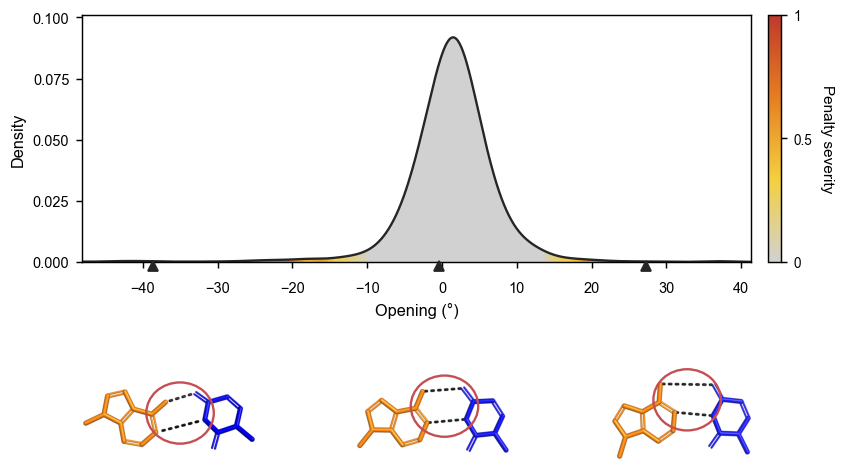

In [25]:
from matplotlib.transforms import offset_copy

EXAMPLES = [("3C_open_closed", -38.58), ("3C_open_ideal", -0.42), ("3C_open_open", 27.32)]

def tight_crops(names, pad=8, thresh=246):
    out = []
    for n in names:
        im = Image.open(RENDERS / f"{n}.png").convert("RGB")
        l, t_, r, b_ = ImageOps.grayscale(im).point(lambda v: 255 if v < thresh else 0).getbbox()
        dst = RENDERS / "cropped" / f"{n}_tight.png"
        dst.parent.mkdir(exist_ok=True)
        im.crop((max(0, l - pad), max(0, t_ - pad), min(im.width, r + pad),
                 min(im.height, b_ + pad))).save(dst)
        out.append(dst)
    return out


FOCUS_RED = "#C44E52"
RINGED = {"3C_open_closed", "3C_open_ideal", "3C_open_open"}


def dash_box(path):
    rgb = np.asarray(Image.open(path).convert("RGB")).astype(int)
    dark_grey = (rgb.max(axis=2) < 90) & (rgb.max(axis=2) - rgb.min(axis=2) < 30)
    ys, xs = np.nonzero(dark_grey)
    return xs.min(), xs.max(), ys.min(), ys.max()


def focus_ring(ax_i, box, size):
    from matplotlib.patches import Ellipse
    x0, x1, y0, y1 = box
    ax_i.add_patch(Ellipse(((x0 + x1) / 2, (y0 + y1) / 2), *size, fill=False,
                           ec=FOCUS_RED, lw=1.3, clip_on=False, zorder=5))


def draw_c(fig, ax, band_y0, band_h, band_x0=None, band_w=None):
    cal_panel(ax, "pairs", "opening", "pairs", "Opening (°)", include=[d for _, d in EXAMPLES])
    ax.tick_params(axis="x", pad=7)
    W, H = fig.get_size_inches()
    box = ax.get_position()
    crops = tight_crops([n for n, _ in EXAMPLES])
    px = [Image.open(p).size for p in crops]
    scale = TARGET_SPAN_IN / PX_PER_PYRIMIDINE["3C"]          # inches per pixel, same base size as Figure 4
    widths = [w * scale / W for w, _ in px]
    heights = [h * scale / H for _, h in px]
    bx0 = box.x0 if band_x0 is None else band_x0          # example row may be wider than the frame
    bw = box.width if band_w is None else band_w
    gap = (bw - sum(widths)) / (len(EXAMPLES) - 1)
    boxes = {n: dash_box(p) for (n, _), p in zip(EXAMPLES, crops) if n in RINGED}
    ring = (1.35 * max(b[1] - b[0] for b in boxes.values()),
            1.6 * max(b[3] - b[2] for b in boxes.values()))
    x = bx0
    for (name, d), iw, ih, path in zip(EXAMPLES, widths, heights, crops):
        ax_i = fig.add_axes([x, band_y0 + (band_h - ih) / 2, iw, ih])
        x += iw + gap
        ax_i.imshow(plt.imread(path))
        ax_i.set_axis_off()
        if name in RINGED:
            focus_ring(ax_i, boxes[name], ring)
        ms = 5
        ax.plot([d], [0], marker="^", ms=ms, color="0.15", clip_on=False, zorder=5,
                transform=offset_copy(ax.transData, fig=fig, y=-ms / 2, units="points"))
    return ax

fig = plt.figure(figsize=(6.6, 3.8))
ax = fig.add_axes([0.1, 0.45, 0.78, 0.5])
draw_c(fig, ax, 0.02, 0.22)
cb = severity_colorbar(fig, [ax], cax=fig.add_axes([0.9, 0.45, 0.015, 0.5]))
save(fig, "figures/main/figure3_A_opening_examples.png")
plt.show()

## Panel B, top
Reference and flagged pairs and their scores

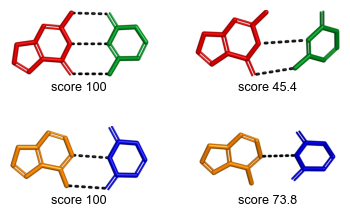

In [26]:
# Ideal and distorted pairs with their scores
# (pair types, G-C cWW and A-U cWW, are given in the caption, not on the figure)
EXAMPLE_PAIRS = {p["role"]: p for p in _json("reference/figure3/example_pairs.json")["pairs"]}
score_of = lambda role: round(EXAMPLE_PAIRS[role]["score"], 1)
PAIR_GRID = [[("1C_ideal_GC", score_of("G-C ideal")), ("5C_orig", score_of("G-C distorted"))],
             [("1C_ideal_AU", score_of("A-U ideal")), ("1C_distorted_AU", score_of("A-U distorted"))]]


def draw_pairs(fig, x0, top, width, height, label_h=0.17, row_gap=0.20):
    """2 x 2 block (rows G-C and A-U; columns ideal, distorted) at the Figure 4 base size,
    row_gap inches between the rows, the block centred vertically in the given height."""
    W, H = fig.get_size_inches()
    scale = TARGET_SPAN_IN / PX_PER_PYRIMIDINE["pairs"]
    rows = [[(plt.imread(autocrop(f"{n}.png")), s) for n, s in row] for row in PAIR_GRID]
    row_h = [max(im.shape[0] for im, _ in row) * scale + label_h for row in rows]
    y, col_w = top + (height - sum(row_h) - row_gap) / 2, width / 2
    for row, rh in zip(rows, row_h):
        img_h = rh - label_h
        for k, (im, score) in enumerate(row):
            iw, ih = im.shape[1] * scale, im.shape[0] * scale
            cx = x0 + (k + 0.5) * col_w
            ax_i = fig.add_axes([(cx - iw / 2) / W, 1 - (y + (img_h + ih) / 2) / H, iw / W, ih / H])
            ax_i.imshow(im); ax_i.set_axis_off()
            fig.text(cx / W, 1 - (y + img_h + 0.03) / H, f"score {score:g}", ha="center", va="top",
                     fontsize=7, color="black")
        y += rh + row_gap


fig = plt.figure(figsize=(3.0, 2.0))
draw_pairs(fig, 0.05, 0.05, 2.9, 1.9)
save(fig, "figures/main/figure3_B_example_pairs.png")
plt.show()


## Panel B, bottom
Points lost per parameter for the two flagged pairs

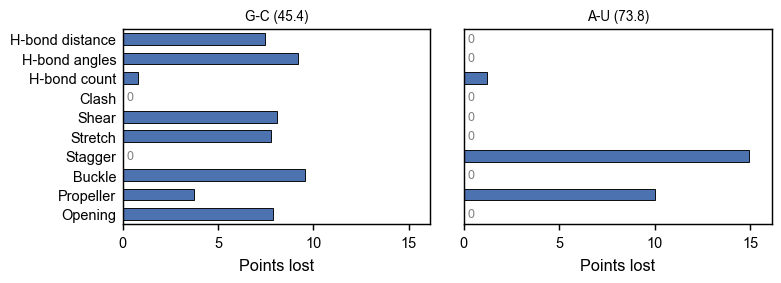

In [27]:
# Severities of the flagged properties of the two distorted pairs in B (`rubric --details`, written by
# scripts/data_gen/extract_figure3_examples.py); penalty = weight x severity, score = 100 - sum.
ORANGE = "#DD8452"
BAR_BLUE = "#4C72B0"                       # paper blue; bars have black borders as in the other figures
WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUE_NAME = {"distance": "H-bond distance", "hbond_angles": "H-bond angles", "incorrect_hbond_count": "H-bond count",
              "stretch": "Stretch", "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
              "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}
DISTORTED = [(pair, EXAMPLE_PAIRS[role]["score"], EXAMPLE_PAIRS[role]["severity"])
             for pair, role in (("G-C", "G-C distorted"), ("A-U", "A-U distorted"))]
for pair, score, sev in DISTORTED:                  # the bars must add up to the score
    assert abs(100 - sum(WEIGHTS[i] * v for i, v in sev.items()) - score) < 0.06, pair


PARAM_ORDER = ["distance", "hbond_angles", "incorrect_hbond_count", "clash",      # hydrogen bonds, clash,
               "shear", "stretch", "stagger", "buckle", "propeller", "opening"]  # then the rigid-body parameters
assert set(PARAM_ORDER) == set(WEIGHTS)


def draw_penalties(axes, titles=True, lollipop=False):
    """One frame per distorted pair (G-C, A-U): horizontal bars for all ten scored parameters in the same
    order and on the same x scale; parameters that cost nothing are marked with a grey 0. Only the first frame
    carries the parameter names. lollipop=True (combined figure only) draws each value as a dot on a grey
    guide line from 0, as in Figure 2C-E; parameters that cost nothing get a small grey dot at 0."""
    xmax = max(max(WEIGHTS[i] * v for i, v in sev.items()) for _, _, sev in DISTORTED) * 1.08
    ys = np.arange(len(PARAM_ORDER))
    for k, (ax, (pair, score, sev)) in enumerate(zip(axes, DISTORTED)):
        lost = [WEIGHTS[i] * sev.get(i, 0.0) for i in PARAM_ORDER]
        if lollipop:
            lost_a = np.asarray(lost)
            hit = lost_a > 0
            ax.hlines(ys[hit], 0, lost_a[hit], color="0.78", lw=0.8, zorder=1)
            ax.scatter(lost_a[hit], ys[hit], s=26, color=BAR_BLUE, zorder=3, edgecolors="black",
                       linewidths=0.6, clip_on=False)
            ax.scatter(np.zeros((~hit).sum()), ys[~hit], s=12, color="0.75", zorder=3, edgecolors="0.45",
                       linewidths=0.5, clip_on=False)
        else:
            ax.barh(ys, lost, height=0.6, color=BAR_BLUE, edgecolor="black", linewidth=0.5)
            for y, v in zip(ys, lost):               # scored but cost nothing: a grey zero, not a blank row
                if v == 0:
                    ax.text(0.012 * xmax, y, "0", ha="left", va="center", fontsize=7, color="0.5")
        ax.set_yticks(ys)
        ax.set_yticklabels([ISSUE_NAME[i] for i in PARAM_ORDER] if k == 0 else [])
        ax.set_ylim(len(PARAM_ORDER) - 0.5, -0.5)          # first parameter at the top
        ax.set_xlim(0, xmax)
        ax.set_xticks(np.arange(0, xmax, 5))
        ax.set_xlabel("Points lost")
        if titles:
            ax.text(0.5, 1.03, f"{pair} ({score:.1f})", transform=ax.transAxes, ha="center", va="bottom", fontsize=7.5)
        finish(ax)
        ax.tick_params(axis="y", length=0)           # after finish(), which resets tick lengths


fig = plt.figure(figsize=(6.4, 2.2))
draw_penalties([fig.add_axes([0.2, 0.2, 0.37, 0.68]), fig.add_axes([0.61, 0.2, 0.37, 0.68])])
save(fig, "figures/main/figure3_C_points_lost.png")
plt.show()


## Combined figure

  [canonicalize/pairs] swapped 141,951 rows into canonical orientation
saved 6.72 x 6.33 in; at 6.73 in wide the smallest text prints at 7.00 pt
text 7.0 pt, axis titles 8.5 pt, panel letters 12.0 pt at 6.73 in (6.72 in saved)


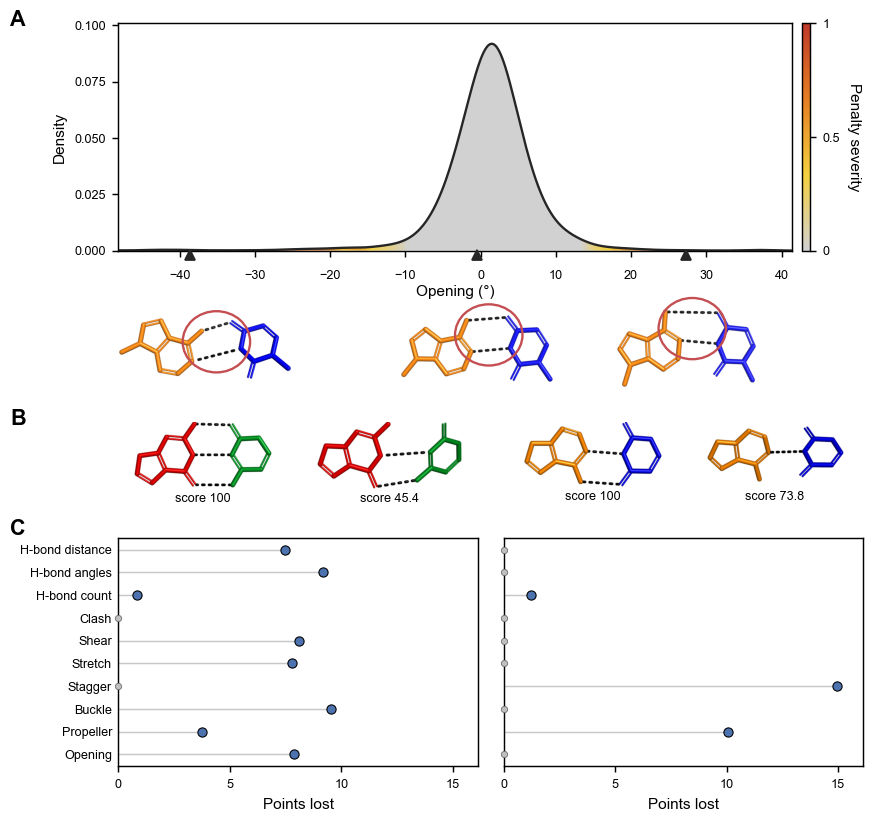

In [28]:
def draw_c_aligned(fig, ax, band_y0, band_h):
    """As draw_c, but each example render is centred under its triangle on the opening axis."""
    cal_panel(ax, "pairs", "opening", "pairs", "Opening (°)", include=[d for _, d in EXAMPLES])
    ax.tick_params(axis="x", pad=7)
    W, H = fig.get_size_inches()
    crops = tight_crops([n for n, _ in EXAMPLES])
    px = [Image.open(p).size for p in crops]
    scale = TARGET_SPAN_IN / PX_PER_PYRIMIDINE["3C"]
    boxes = {n: dash_box(p) for (n, _), p in zip(EXAMPLES, crops) if n in RINGED}
    ring = (1.35 * max(b[1] - b[0] for b in boxes.values()),
            1.6 * max(b[3] - b[2] for b in boxes.values()))
    to_fig = fig.transFigure.inverted()
    box = ax.get_position()
    for (name, d), (w, h), path in zip(EXAMPLES, px, crops):
        iw, ih = w * scale / W, h * scale / H
        cx = to_fig.transform(ax.transData.transform((d, 0)))[0]
        cx = min(max(cx, box.x0 + iw / 2), box.x1 - iw / 2)      # keep the render under the frame
        ax_i = fig.add_axes([cx - iw / 2, band_y0 + (band_h - ih) / 2, iw, ih])
        ax_i.imshow(plt.imread(path)); ax_i.set_axis_off()
        if name in RINGED:
            focus_ring(ax_i, boxes[name], ring)
        ms = 5
        ax.plot([d], [0], marker="^", ms=ms, color="0.15", clip_on=False, zorder=5,
                transform=offset_copy(ax.transData, fig=fig, y=-ms / 2, units="points"))
    return ax


def draw_pairs_cols(fig, halves, top, label_h=0.17, head_h=0.0, pair_gap=0.35):
    """Top of B, grouped by pair type: G-C (reference, flagged) in the left half, A-U in the right."""
    W, H = fig.get_size_inches()
    scale = TARGET_SPAN_IN / PX_PER_PYRIMIDINE["pairs"]
    used = 0
    for (x0, w), (name, row) in zip(halves, (("G-C", PAIR_GRID[0]), ("A-U", PAIR_GRID[1]))):
        ims = [(plt.imread(autocrop(f"{n}.png")), sc) for n, sc in row]
        img_h = max(im.shape[0] for im, _ in ims) * scale
        y = top + head_h
        widths = [im.shape[1] * scale for im, _ in ims]
        left = x0 + (w - sum(widths) - pair_gap * (len(ims) - 1)) / 2     # group centred over its bar frame
        for k, (im, score) in enumerate(ims):
            iw, ih = im.shape[1] * scale, im.shape[0] * scale
            cx = left + sum(widths[:k]) + pair_gap * k + iw / 2
            ax_i = fig.add_axes([(cx - iw / 2) / W, 1 - (y + (img_h + ih) / 2) / H, iw / W, ih / H])
            ax_i.imshow(im); ax_i.set_axis_off()
            fig.text(cx / W, 1 - (y + img_h + 0.03) / H, f"score {score:g}", ha="center", va="top",
                     fontsize=7, color="black")
        used = max(used, head_h + img_h + label_h)
    return used


FIG_W = 6.73                               # RSC double column (17.1 cm); saved at this width
LX, RX_END = 0.85, 6.58                    # left edge of the frames (room for the parameter names); right edge
W_ALL = RX_END - LX
C_GAP = 0.20                               # gap between the two bar frames (they share the parameter names)
HALF = (W_ALL - C_GAP) / 2
HALVES = [(LX, HALF), (LX + HALF + C_GAP, HALF)]
C_D_H = 1.75                               # frame height shared by A and the bar frames of B
ROW1, A_H, BAND_GAP, BAND_H = 0.25, C_D_H, 0.355, 0.80
ROW2 = ROW1 + A_H + BAND_GAP + BAND_H + 0.16
_PAIR_SCALE = TARGET_SPAN_IN / PX_PER_PYRIMIDINE["pairs"]
B_H = max(max(plt.imread(autocrop(f"{n}.png")).shape[0] for n, _ in row)
          for row in PAIR_GRID) * _PAIR_SCALE + 0.17     # renders + score labels
PANEL_GAP = ROW2 - (ROW1 + A_H + BAND_GAP + BAND_H)      # space above B, used again above C
C_DROP = 0.05                              # C's parameter names reach into the letter column
ROW3 = ROW2 + B_H + PANEL_GAP + C_DROP     # same white space above C as above B
FIG_H = ROW3 + C_D_H + 0.45
fig = plt.figure(figsize=(FIG_W, FIG_H))
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]

# A across the full width, its examples beneath
A_W = W_ALL - 0.55                         # leave room for the colour bar and its label
ax_a = fig.add_axes(inch(LX, ROW1, A_W, A_H))
band = inch(LX, ROW1 + A_H + BAND_GAP, A_W, BAND_H)
draw_c_aligned(fig, ax_a, band[1], band[3])
ax_a.xaxis.labelpad = 2
cax = fig.add_axes(inch(LX + A_W + 0.08, ROW1, 0.06, A_H))
severity_colorbar(fig, [ax_a], cax=cax).set_ticklabels(["0", "0.5", "1"])

# B: pairs grouped by type, each half above its bar frame in C
draw_pairs_cols(fig, HALVES, ROW2)

# C: points lost, one frame per pair type under its pairs in B
ax_c1 = fig.add_axes(inch(HALVES[0][0], ROW3, HALF, C_D_H))
ax_c2 = fig.add_axes(inch(HALVES[1][0], ROW3, HALF, C_D_H))
draw_penalties([ax_c1, ax_c2], titles=False, lollipop=True)

for s_, x, y in (("A", 0.02, ROW1 - 0.1), ("B", 0.02, ROW2 - 0.1), ("C", 0.02, ROW3 - C_DROP - 0.1)):
    fig.text(x / FIG_W, 1 - y / FIG_H, s_, fontsize=12, fontweight="bold", ha="left", va="top")

TEXT_PT, LETTER_PT = 7, 12


def set_uniform_text(fig, size=TEXT_PT):
    import matplotlib.text as mtext
    for t in fig.findobj(mtext.Text):
        if t.get_fontsize() >= LETTER_PT and t.get_fontweight() in ("bold", 700):
            continue
        if t.get_fontweight() in ("bold", 700):
            t.set_fontsize(size + 0.5)
            continue
        t.set_fontsize(size)


def _ensure_print_pt(fig, min_pt=7.0, page_in=6.73, pad=0.08):
    import matplotlib.text as mtext
    texts = [t for t in fig.findobj(mtext.Text) if t.get_visible() and t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        smallest = min(t.get_fontsize() for t in texts) / shrink
        if smallest >= min_pt - 1e-3:
            break
        for t in texts:
            t.set_fontsize(t.get_fontsize() * min_pt / smallest * 1.005)
    print(f"saved {bb.width + 2 * pad:.2f} x {bb.height + 2 * pad:.2f} in; at {page_in} in wide "
          f"the smallest text prints at {smallest:.2f} pt")


set_uniform_text(fig)
enlarge_axis_labels(fig)
_ensure_print_pt(fig)
def _enforce_print_spec(fig, text_pt=7.0, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    """Ticks and other text at text_pt, axis titles at axis_pt, panel letters at letter_pt, as printed at page_in wide."""
    import matplotlib.text as mtext
    axis = {id(lab) for ax in fig.axes for lab in (ax.xaxis.label, ax.yaxis.label)}
    letters = {id(t) for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)}
    texts = [t for t in fig.findobj(mtext.Text) if t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for t in texts:
            t.set_fontsize((letter_pt if id(t) in letters else axis_pt if id(t) in axis else text_pt) * shrink)
    print(f"text {text_pt} pt, axis titles {axis_pt} pt, panel letters {letter_pt} pt at {page_in} in "
          f"({bb.width + 2 * pad:.2f} in saved)")


_enforce_print_spec(fig)
save(fig, "figures/main/figure3.png")
plt.show()
